In [ ]:
import pandas as pd


In [ ]:
train = pd.read_csv("train.csv")

In [ ]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 18045 entries, 0 to 18044
Data columns (total 36 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Transaction_ID        18045 non-null  str    
 1   Order_ID              18045 non-null  str    
 2   Customer_ID           18045 non-null  str    
 3   Customer_Name         17937 non-null  str    
 4   Customer_Age          17827 non-null  float64
 5   Customer_Gender       17883 non-null  str    
 6   Customer_Segment      18045 non-null  str    
 7   Order_Date            18045 non-null  str    
 8   Order_Time            18045 non-null  str    
 9   Sales_Channel         18045 non-null  str    
 10  Store_ID              18045 non-null  str    
 11  Store_Name            18045 non-null  str    
 12  Country               18045 non-null  str    
 13  Region                18045 non-null  str    
 14  City                  18045 non-null  str    
 15  Product_ID            18045 no

In [ ]:
train.describe(include="all")

,Transaction_ID,Order_ID,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Segment,Order_Date,Order_Time,Sales_Channel,...,Order_Status,Shipping_Method,Delivery_Days,Return_Flag,Return_Reason,Sales_Representative,Promotion_Code,Customer_Rating,Inventory_Level,Order_Year
count,18045,18045,18045,17937,17827.000000,17883,18045,18045,18045,18045,...,18045,18045,17883.000000,18045,1877,18045,8308,14610.000000,17847.000000,18045.000000
unique,18000,14541,4882,1179,NaN,6,6,1461,15201,4,...,8,4,NaN,2,6,16,10,NaN,NaN,NaN
top,T02009714,O0102892,C02559,Amelia King,NaN,Female,Consumer,2024-12-25,12:29:48,Online,...,Completed,Standard,NaN,No,Late Delivery,Sophia Brown,HOLIDAY20,NaN,NaN,NaN
freq,2,4,21,58,NaN,8742,8039,33,5,8211,...,11462,7754,NaN,16168,331,1166,1399,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,38.916924,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,2.262204,NaN,NaN,NaN,NaN,3.985969,70.257914,2023.566417
std,NaN,NaN,NaN,NaN,10.727357,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,2.321656,NaN,NaN,NaN,NaN,1.008422,22.042609,1.118744
min,NaN,NaN,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,1.000000,0.000000,2022.000000
25%,NaN,NaN,NaN,NaN,32.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,4.000000,55.000000,2023.000000
50%,NaN,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,4.000000,70.000000,2024.000000
75%,NaN,NaN,NaN,NaN,46.000000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,5.000000,85.000000,2025.000000


In [ ]:
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Customer_Name        108
Customer_Age         218
Customer_Gender      162
Product_Name         144
Payment_Method       147
Delivery_Days        162
Return_Reason      16168
Promotion_Code      9737
Customer_Rating     3435
Inventory_Level      198
dtype: int64

In [ ]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [ ]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [ ]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['object','string']).columns

for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

In [ ]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

In [ ]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

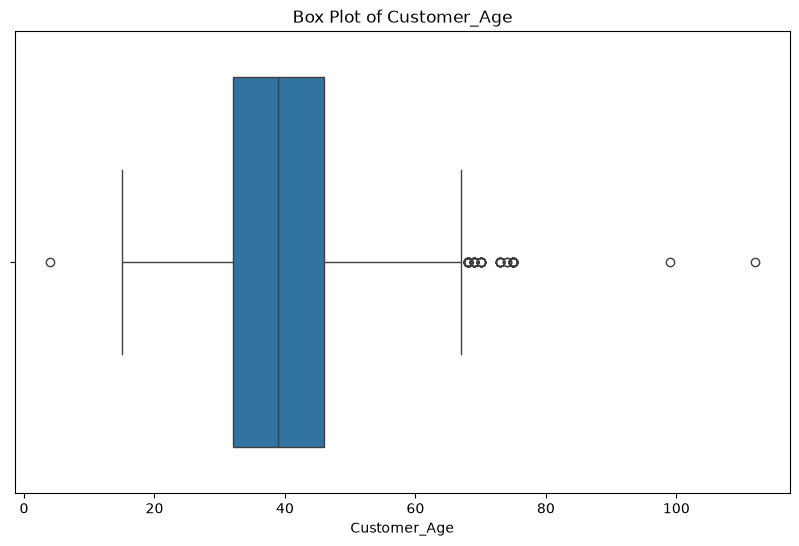

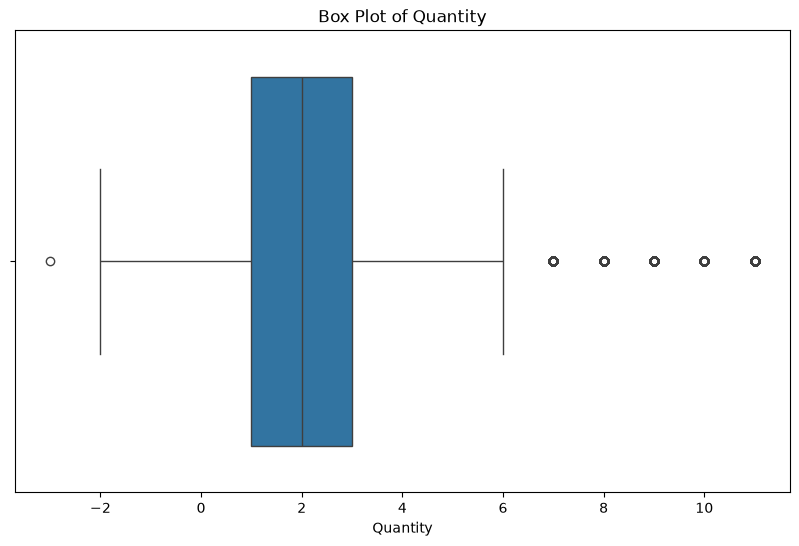

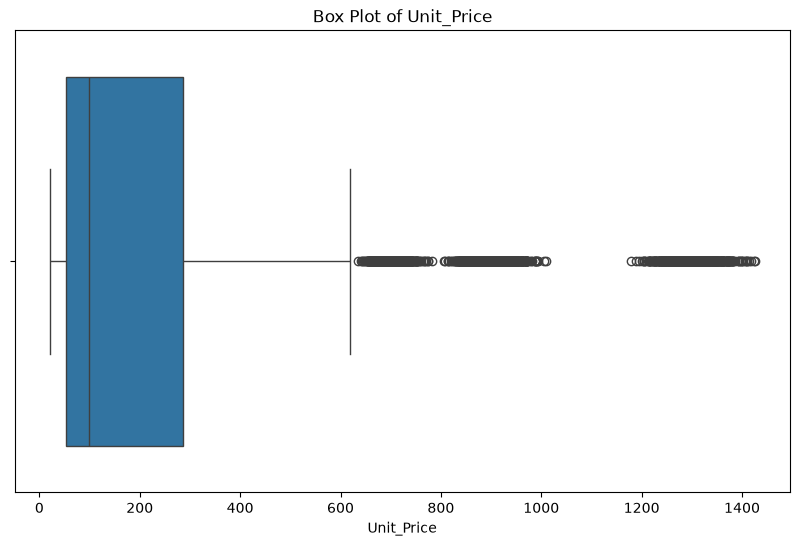

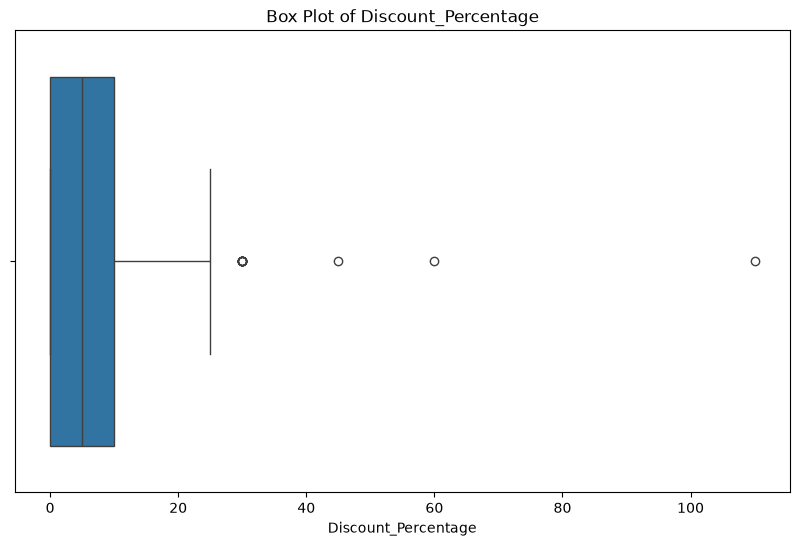

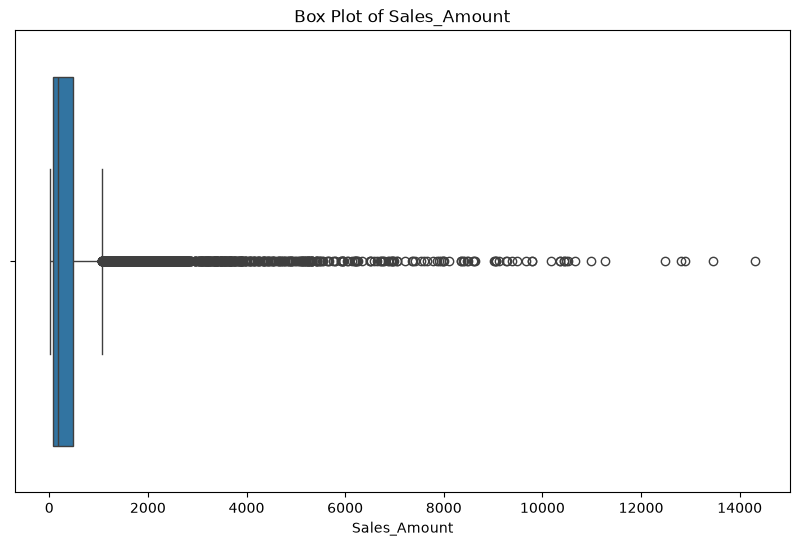

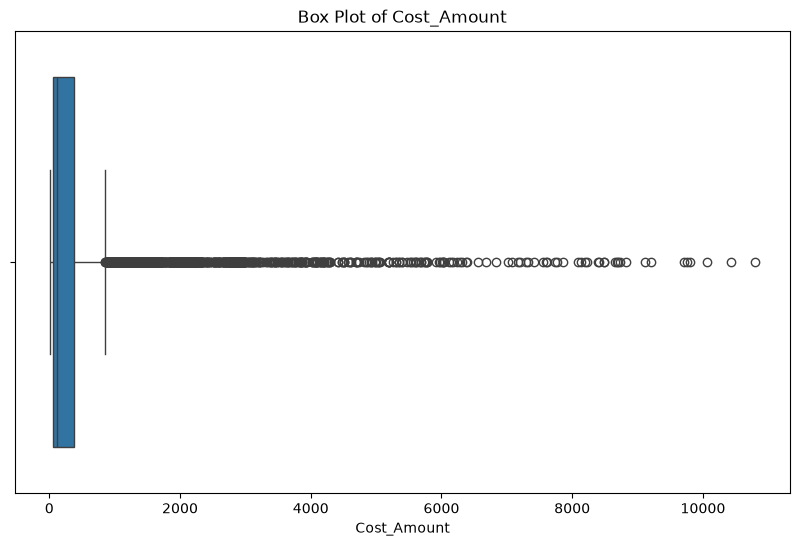

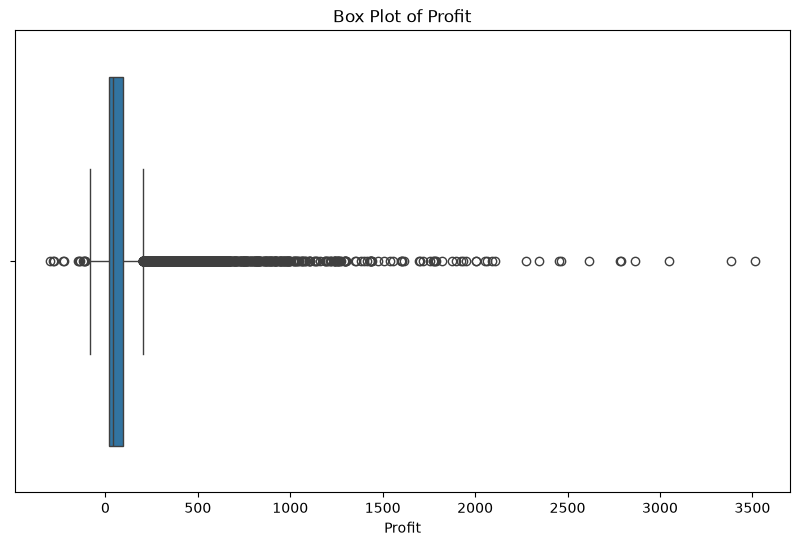

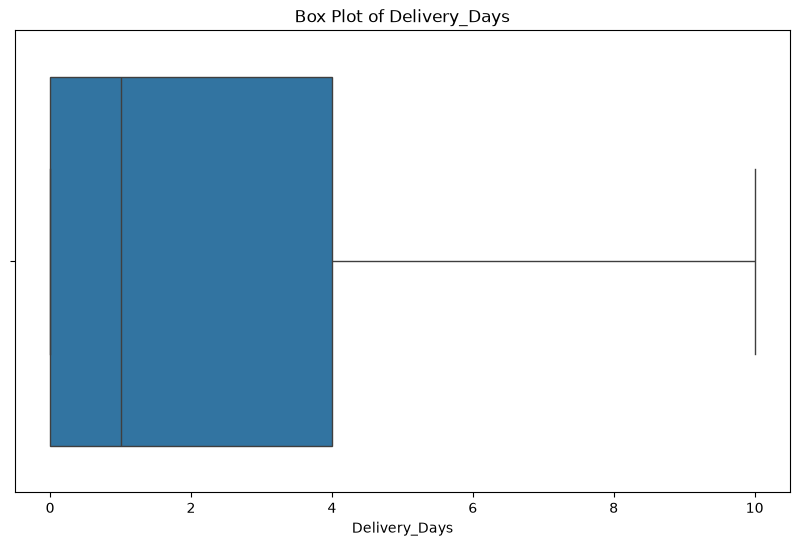

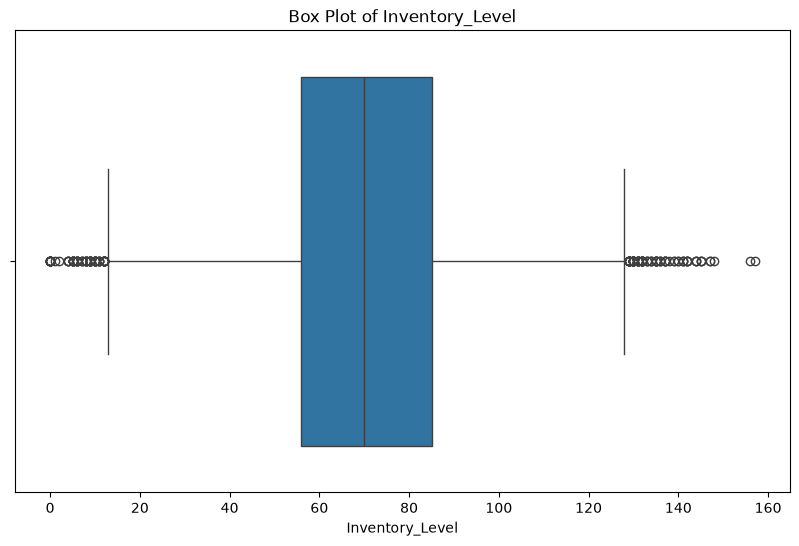

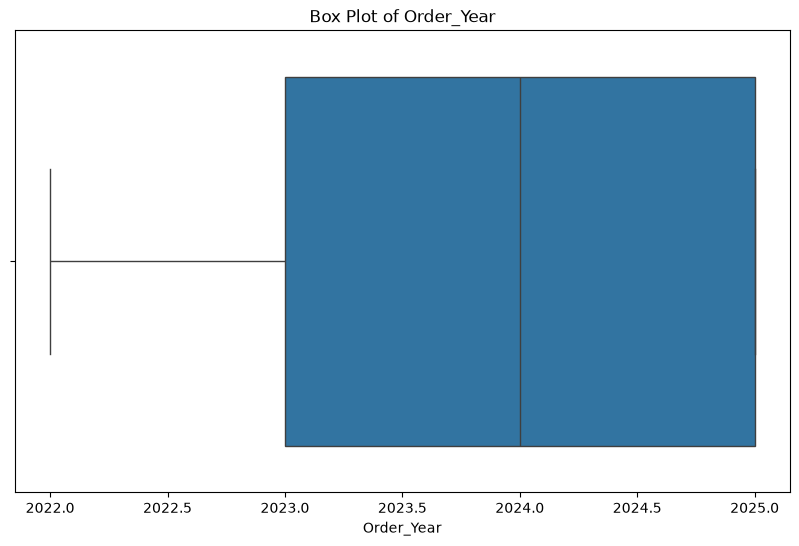

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [ ]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [ ]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 *IQR)) | (df[numeric_features] > (Q3 + 1.5* IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object','string']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

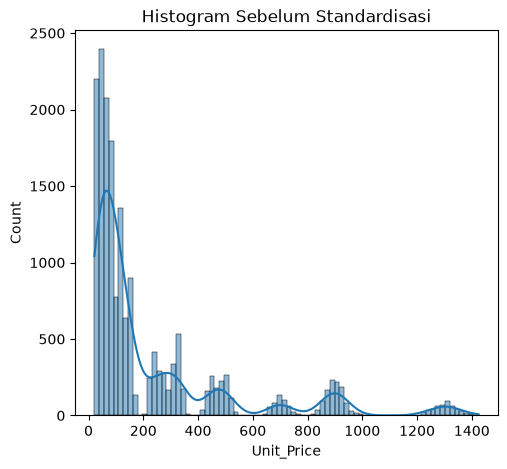

In [ ]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[2]], kde=True)
plt.title("Histogram Sebelum Standardisasi")
plt.show()

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

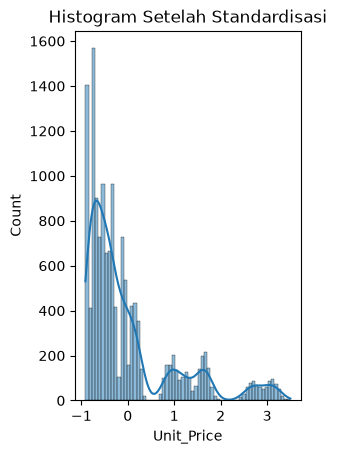

In [ ]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[2]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [ ]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
       Customer_Age  Quantity  Unit_Price  Discount_Percentage  Sales_Amount  \
602        1.269984 -0.724333    1.578599            -0.197932      0.562510   
3868       0.022500 -0.724333   -0.581844            -0.197932     -0.749833   
4133       0.502302  0.193374   -0.860654            -0.930257     -0.763882   
6568       0.406341 -0.724333   -0.039292            -0.930257     -0.386612   
7041      -0.457302  0.193374    0.198269             1.266717      0.342790   
7069      -0.745183 -0.724333    0.057265            -0.930257     -0.324873   
7504       0.310381  1.111082   -0.112951             0.534392      0.630547   
7675       0.118460  3.864203   -0.569469             0.534392      0.744551   
7914      -1.992667 -0.724333   -0.780260            -0.197932     -0.870405   
8825      -1.992667  0.193374    1.225119            -0.930257      1.903489   
9039       0.790183 -0.724333    0.194818            -0.930257     -0.236921   
9128       0.022500  0.1

In [ ]:
# Menghapus baris duplikat
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
       Customer_Age  Quantity  Unit_Price  Discount_Percentage  Sales_Amount  \
0         -1.033064  0.193374   -0.374083            -0.197932     -0.187508   
1          0.694222  3.864203   -0.596660             1.266717      0.555728   
2          0.310381  0.193374   -0.722343             1.266717     -0.657898   
4         -0.169421  2.028789   -0.505238             1.266717      0.216083   
5          0.310381 -0.724333   -0.418952            -0.197932     -0.650900   
...             ...       ...         ...                  ...           ...   
18037     -1.224984  0.193374   -0.885488             0.534392     -0.822015   
18040     -0.649222 -0.724333   -0.307074            -0.930257     -0.557834   
18042     -0.169421 -0.724333    0.254250             0.534392     -0.285042   
18043     -1.704786  0.193374   -0.863095            -0.930257     -0.766896   
18044      1.557865 -0.724333    0.080667            -0.930257     -0.309909   

 

In [ ]:
category_features = df.select_dtypes(include=['object','string']).columns
df[category_features]

,Transaction_ID,Order_ID,Customer_ID,Customer_Name,Customer_Gender,Customer_Segment,Order_Date,Order_Time,Sales_Channel,Store_ID,...,City,Product_ID,Product_Name,Product_Category,Product_Subcategory,Payment_Method,Order_Status,Shipping_Method,Return_Flag,Sales_Representative
0,T02016694,O0116694,C01482,Sophia Smith,Male,Consumer,2022-10-06,11:30:55,Online,LA-01,...,LOS ANGELES,P026,Webcam HD,Electronics,Cameras,Credit Card,Completed,Standard,No,James Anderson
1,T02016374,O0108187,C01591,Hannah King,Female,Consumer,2024-06-03,17:06:29,Online,SYD-01,...,Sydney,P005,Office Keyboard,Electronics,Accessories,Debit Card,Completed,Standard,No,Ella Lewis
2,T02004099,O0104099,C04140,Emma Wilson,Male,Consumer,2024-12-19,08:22:11,Online,PAR-01,...,Paris,P017,Copy Paper Box,Office Supplies,Paper,Credit Card,Shipped,Standard,No,Liam Davis
4,T02012685,O0112685,C02749,Sophia Smith,Male,Returning Customer,2022-09-13,14:55:16,B2B Portal,CHI-01,...,Chicago,P013,Desk Lamp,Furniture,Lighting,Apple Pay,Completed,Express,No,Sophia Brown
5,T02003704,O0101852,C00959,Mia Miller,Non-binary,Corporate,2023-03-27,10:40:05,Retail Store,TOR-01,...,Toronto,P012,Ergo Footrest,Furniture,Office Furniture,Debit Card,Completed,Pickup,No,Noah Wilson
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18037,T02007434,O0107434,C02487,Isla Thomas,Female,Consumer,2023-12-07,14:13:26,Phone Order,AUS-01,...,Austin,P018,Premium Pens,Office Supplies,Writing,DebitCard,Shipped,Standard,No,Mia Taylor
18040,T02006253,O0106253,C03487,Ella Adams,Male,New Customer,2022-01-11,10:44:18,Online,SYD-01,...,Sydney,P023,Portable Heater,Appliances,Climate,Credit Card,Completed,Express,No,Emma Carter
18042,T02011672,O0111672,C03311,Oscar Williams,Male,Corporate,2025-04-02,17:45:09,Online,LON-01,...,London,P027,Security Camera,Electronics,Cameras,Apple Pay,Completed,Standard,No,Sophia Brown
18043,T02013094,O0113094,C01590,Benjamin Moore,Female,New Customer,2022-06-08,15:03:38,Online,COL-01,...,Cologne,P019,Notebook Pack,Office Supplies,Paper,Debit Card,Completed,Standard,No,Noah Wilson


In [ ]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,Customer_Age,Quantity,Unit_Price,Discount_Percentage,Sales_Amount,Cost_Amount,Profit,Delivery_Days,Inventory_Level,Order_Year,...,Sales_Representative_Grace Harris,Sales_Representative_Henry White,Sales_Representative_James Anderson,Sales_Representative_Liam Davis,Sales_Representative_Lucas Moore,Sales_Representative_Mia Taylor,Sales_Representative_Michael Clark,Sales_Representative_Noah Wilson,Sales_Representative_Olivia Martin,Sales_Representative_Sophia Brown
0,-1.033064,0.193374,-0.374083,-0.197932,-0.187508,-0.242066,0.060182,0.764114,0.489878,-1.415831,...,False,False,True,False,False,False,False,False,False,False
1,0.694222,3.864203,-0.596660,1.266717,0.555728,0.546704,0.488115,1.627182,2.497324,0.381040,...,False,False,False,False,False,False,False,False,False,False
2,0.310381,0.193374,-0.722343,1.266717,-0.657898,-0.517833,-1.092338,0.764114,1.063434,0.381040,...,False,False,False,True,False,False,False,False,False,False
4,-0.169421,2.028789,-0.505238,1.266717,0.216083,0.078536,0.717593,-0.098954,-0.705031,-1.415831,...,False,False,False,False,False,False,False,False,False,True
5,0.310381,-0.724333,-0.418952,-0.197932,-0.650900,-0.667803,-0.467234,-0.962022,-1.708754,-0.517396,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18037,-1.224984,0.193374,-0.885488,0.534392,-0.822015,-0.808091,-0.728762,1.627182,-0.705031,-0.517396,...,False,False,False,False,False,True,False,False,False,False
18040,-0.649222,-0.724333,-0.307074,-0.930257,-0.557834,-0.560849,-0.445952,-0.098954,-0.896216,-1.415831,...,False,False,False,False,False,False,False,False,False,False
18042,-0.169421,-0.724333,0.254250,0.534392,-0.285042,-0.239402,-0.414928,1.627182,-0.609438,1.279476,...,False,False,False,False,False,False,False,False,False,True
18043,-1.704786,0.193374,-0.863095,-0.930257,-0.766896,-0.780735,-0.574153,2.058716,-1.852143,-1.415831,...,False,False,False,False,False,False,False,True,False,False


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil
df_lencoder

,Customer_Age,Quantity,Unit_Price,Discount_Percentage,Sales_Amount,Cost_Amount,Profit,Delivery_Days,Inventory_Level,Order_Year,...,City,Product_ID,Product_Name,Product_Category,Product_Subcategory,Payment_Method,Order_Status,Shipping_Method,Return_Flag,Sales_Representative
0,-1.033064,0.193374,-0.374083,-0.197932,-0.187508,-0.242066,0.060182,0.764114,0.489878,-1.415831,...,4,21,23,1,2,4,1,3,0,8
1,0.694222,3.864203,-0.596660,1.266717,0.555728,0.546704,0.488115,1.627182,2.497324,0.381040,...,11,2,13,1,0,5,1,3,0,4
2,0.310381,0.193374,-0.722343,1.266717,-0.657898,-0.517833,-1.092338,0.764114,1.063434,0.381040,...,10,12,3,4,10,4,5,3,0,9
4,-0.169421,2.028789,-0.505238,1.266717,0.216083,0.078536,0.717593,-0.098954,-0.705031,-1.415831,...,2,8,5,3,7,0,1,0,0,15
5,0.310381,-0.724333,-0.418952,-0.197932,-0.650900,-0.667803,-0.467234,-0.962022,-1.708754,-0.517396,...,12,7,7,3,9,5,1,2,0,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18037,-1.224984,0.193374,-0.885488,0.534392,-0.822015,-0.808091,-0.728762,1.627182,-0.705031,-0.517396,...,1,13,16,4,15,6,5,3,0,11
18040,-0.649222,-0.724333,-0.307074,-0.930257,-0.557834,-0.560849,-0.445952,-0.098954,-0.896216,-1.415831,...,11,18,14,0,3,4,1,0,0,5
18042,-0.169421,-0.724333,0.254250,0.534392,-0.285042,-0.239402,-0.414928,1.627182,-0.609438,1.279476,...,5,22,19,1,2,0,1,3,0,15
18043,-1.704786,0.193374,-0.863095,-0.930257,-0.766896,-0.780735,-0.574153,2.058716,-1.852143,-1.415831,...,3,14,11,4,10,5,1,3,0,13


In [ ]:
df_lencoder.head()

,Customer_Age,Quantity,Unit_Price,Discount_Percentage,Sales_Amount,Cost_Amount,Profit,Delivery_Days,Inventory_Level,Order_Year,...,City,Product_ID,Product_Name,Product_Category,Product_Subcategory,Payment_Method,Order_Status,Shipping_Method,Return_Flag,Sales_Representative
0,-1.033064,0.193374,-0.374083,-0.197932,-0.187508,-0.242066,0.060182,0.764114,0.489878,-1.415831,...,4,21,23,1,2,4,1,3,0,8
1,0.694222,3.864203,-0.596660,1.266717,0.555728,0.546704,0.488115,1.627182,2.497324,0.381040,...,11,2,13,1,0,5,1,3,0,4
2,0.310381,0.193374,-0.722343,1.266717,-0.657898,-0.517833,-1.092338,0.764114,1.063434,0.381040,...,10,12,3,4,10,4,5,3,0,9
4,-0.169421,2.028789,-0.505238,1.266717,0.216083,0.078536,0.717593,-0.098954,-0.705031,-1.415831,...,2,8,5,3,7,0,1,0,0,15
5,0.310381,-0.724333,-0.418952,-0.197932,-0.650900,-0.667803,-0.467234,-0.962022,-1.708754,-0.517396,...,12,7,7,3,9,5,1,2,0,13


In [ ]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100
 
missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)
 
missing_data[missing_data['Missing Values'] > 0] # Menampilkan kolom dengan missing values

,Missing Values,Percentage


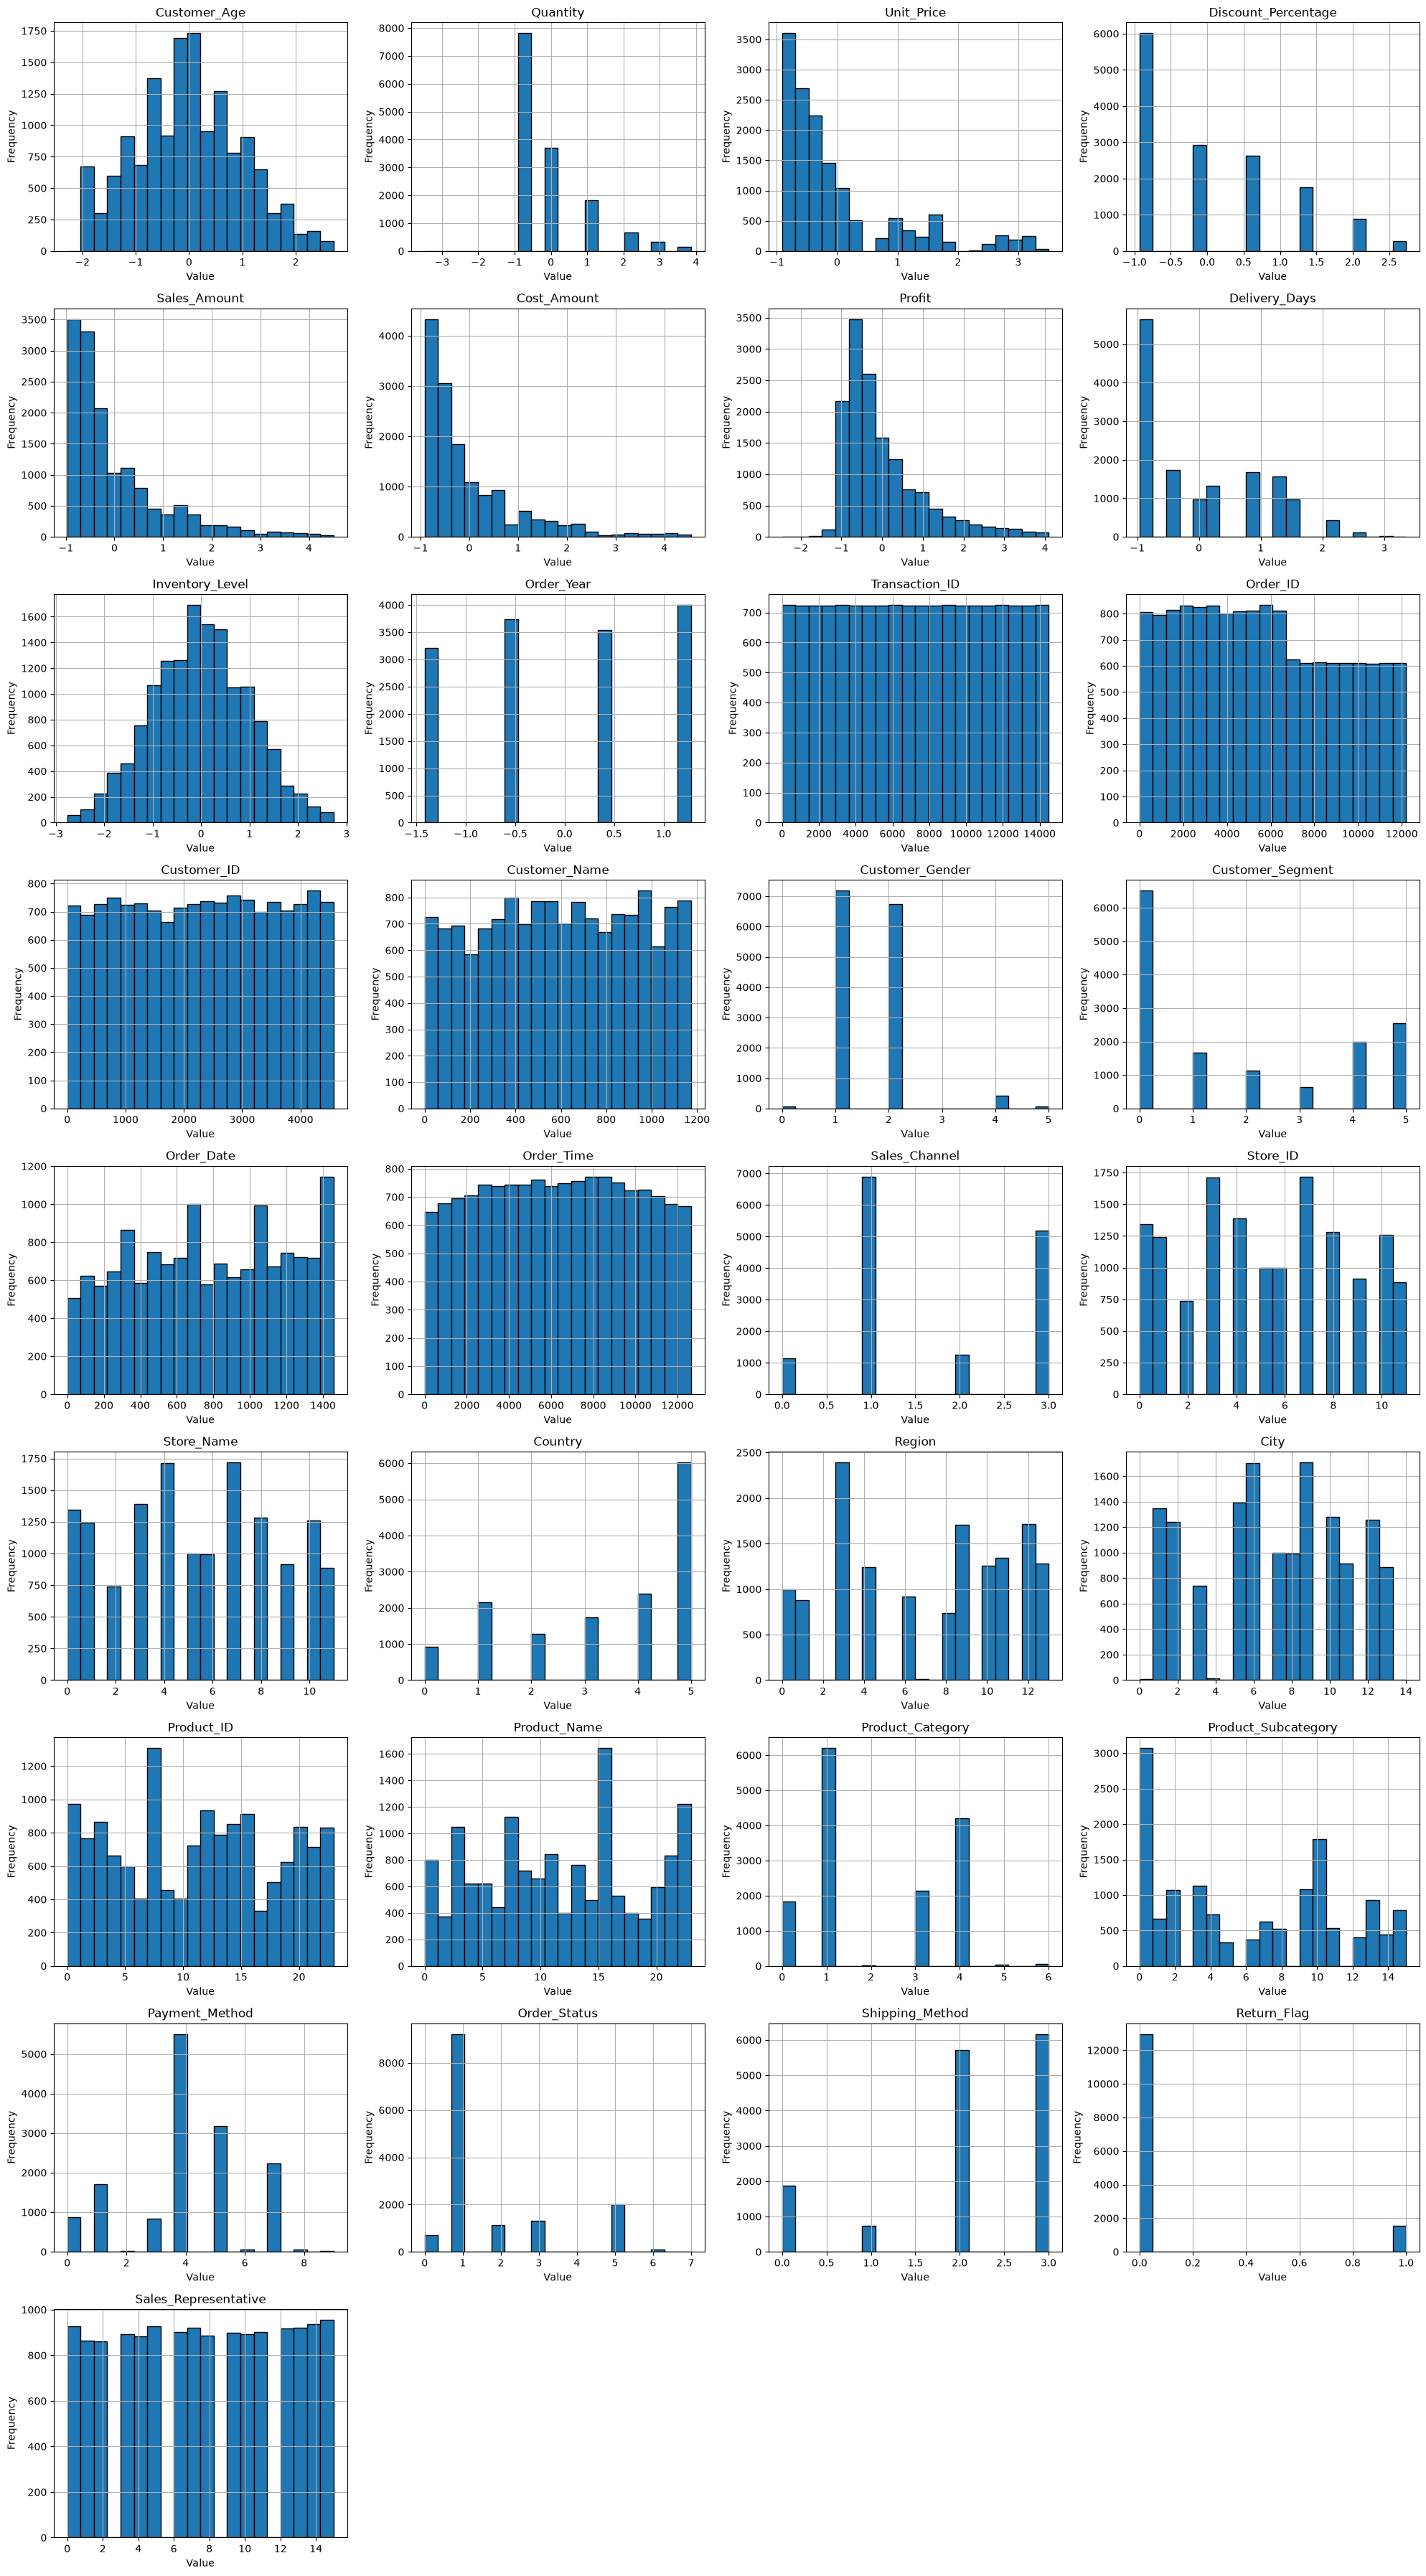

In [ ]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4 # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols) # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()


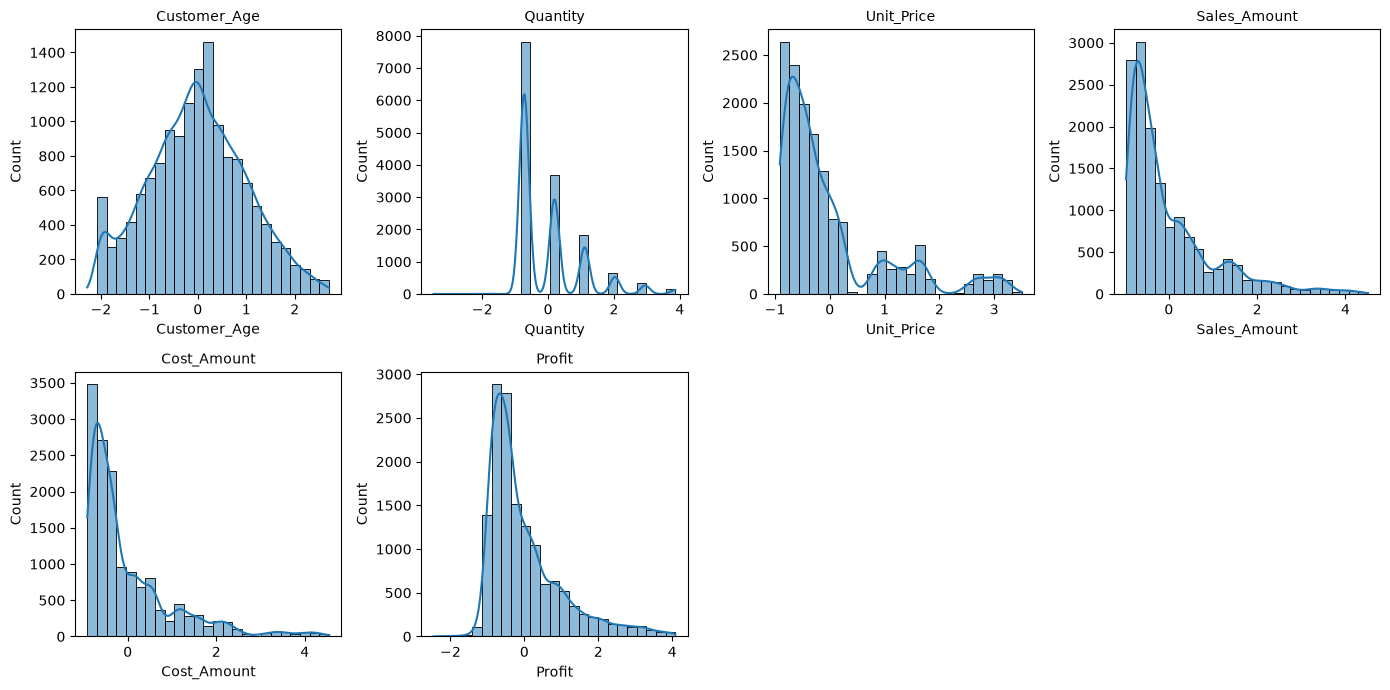

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Pilih kolom numerik utama saja agar tidak terlalu banyak
cols = ['Customer_Age', 'Quantity', 'Unit_Price', 'Sales_Amount', 'Cost_Amount', 'Profit']

# Pengaturan grid (4 kolom per baris)
n_cols = 4
n_rows = math.ceil(len(cols) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 3.5))
axes = axes.flatten()

# Looping untuk membuat plot
for i, col in enumerate(cols):
    sns.histplot(data=df_lencoder, x=col, kde=True, bins=25, ax=axes[i])
    axes[i].set_title(col, fontsize=10)

# Hapus sisa kotak subplot yang kosong (jika ada)
for j in range(len(cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

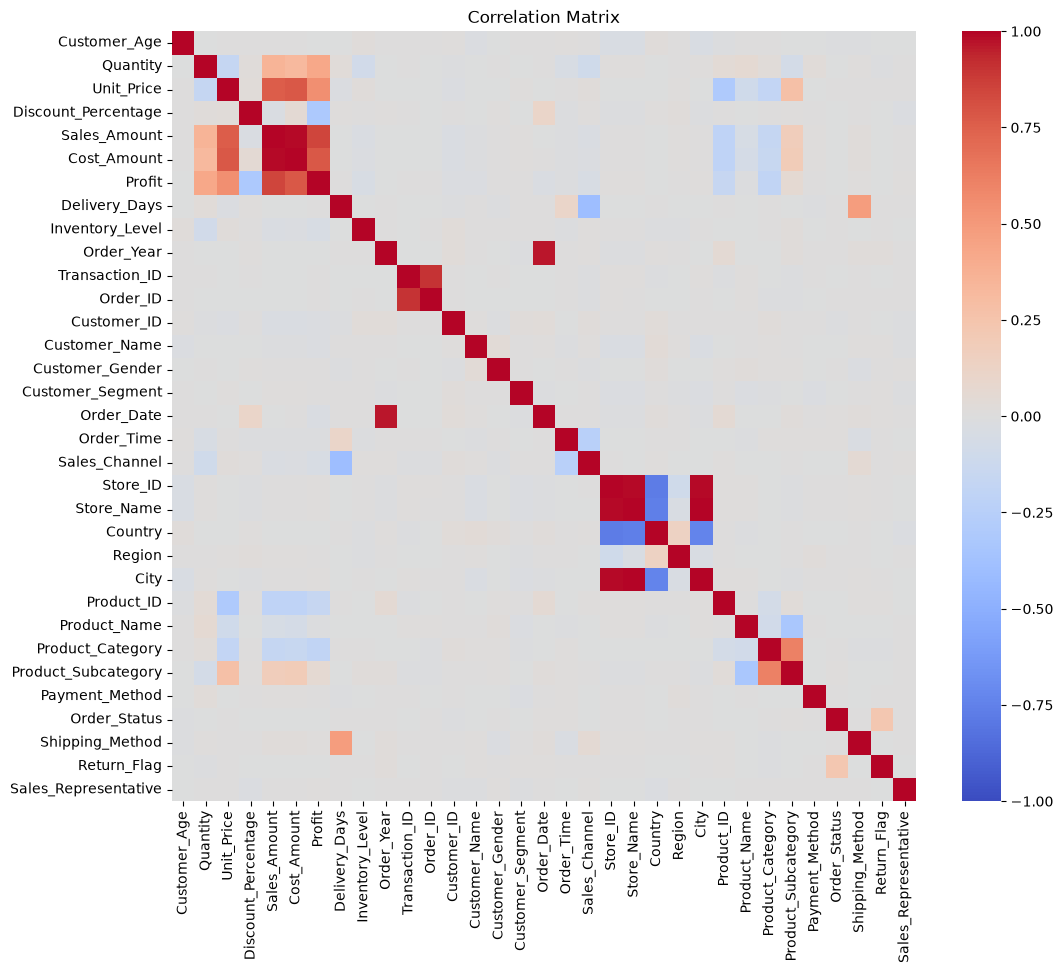

In [ ]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

['Customer_Age', 'Quantity', 'Unit_Price', 'Discount_Percentage', 'Sales_Amount', 'Cost_Amount', 'Profit', 'Delivery_Days', 'Inventory_Level', 'Order_Year', 'Transaction_ID', 'Order_ID', 'Customer_ID', 'Customer_Name', 'Customer_Gender', 'Customer_Segment', 'Order_Date', 'Order_Time', 'Sales_Channel', 'Store_ID', 'Store_Name', 'Country', 'Region', 'City', 'Product_ID', 'Product_Name', 'Product_Category', 'Product_Subcategory', 'Payment_Method', 'Order_Status', 'Shipping_Method', 'Return_Flag', 'Sales_Representative']


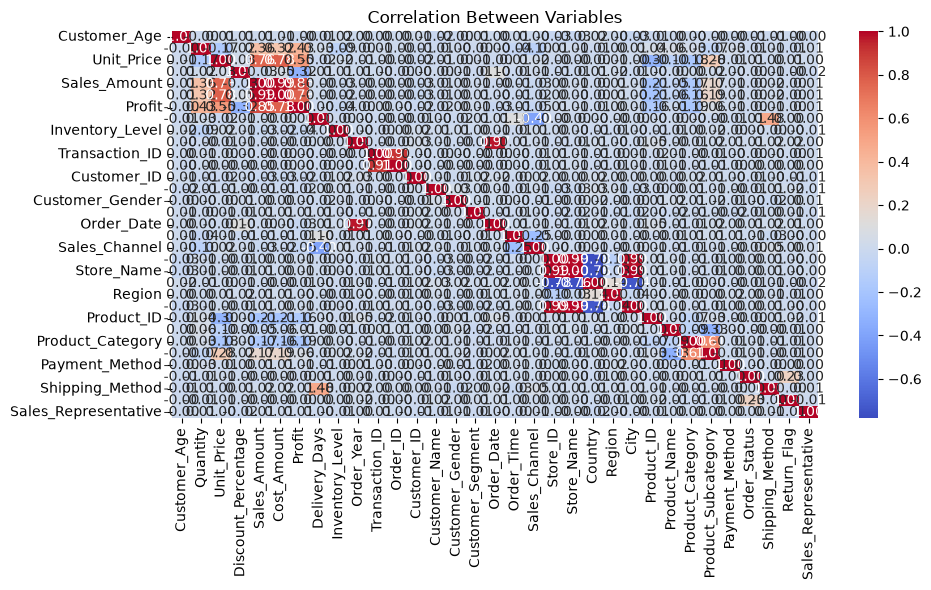

In [ ]:
# Menghitung korelasi dengan tinggi badan
import matplotlib.pyplot as plt
import seaborn as sns

# Melihat nama kolom yang tersedia
print(df_lencoder.columns.tolist())

# Mengambil kolom numerik
numeric_df = df_lencoder.select_dtypes(include='number')

# Menghitung korelasi antarvariabel
target_corr = numeric_df.corr()

# Menampilkan heatmap korelasi
plt.figure(figsize=(10, 6))
sns.heatmap(target_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between Variables')
plt.tight_layout()
plt.show()

In [ ]:
import sklearn

In [ ]:
# Memisahkan fitur (X) dan target (y)
target = 'height'

kolom = next(
    (c for c in df_lencoder.columns
     if target in c.lower()), None
)

if kolom:
    X = df_lencoder.drop(columns=[kolom])
    y = df_lencoder[kolom]

    from sklearn.model_selection import train_test_split

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=1
    )
else:
    print("Kolom height tidak ditemukan:")
    print(df_lencoder.columns.tolist())

Kolom height tidak ditemukan:
['Customer_Age', 'Quantity', 'Unit_Price', 'Discount_Percentage', 'Sales_Amount', 'Cost_Amount', 'Profit', 'Delivery_Days', 'Inventory_Level', 'Order_Year', 'Transaction_ID', 'Order_ID', 'Customer_ID', 'Customer_Name', 'Customer_Gender', 'Customer_Segment', 'Order_Date', 'Order_Time', 'Sales_Channel', 'Store_ID', 'Store_Name', 'Country', 'Region', 'City', 'Product_ID', 'Product_Name', 'Product_Category', 'Product_Subcategory', 'Payment_Method', 'Order_Status', 'Shipping_Method', 'Return_Flag', 'Sales_Representative']


In [ ]:

from sklearn.model_selection import train_test_split

# Memisahkan fitur dan target
X = df_lencoder.drop(columns=['Profit'])
y = df_lencoder['Profit']

# Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

print("Jumlah data:", len(X))
print("Jumlah data latih:", len(X_train))
print("Jumlah data test:", len(X_test))


Jumlah data: 14486
Jumlah data latih: 11588
Jumlah data test: 2898


In [ ]:
# Menghitung jumlah data
print("Jumlah data:", len(X))
print("Jumlah data latih:", len(X_train))
print("Jumlah data test:", len(X_test))

Jumlah data: 14486
Jumlah data latih: 11588
Jumlah data test: 2898
